# Pequeña fábrica con averías: un supervisor para las máquinas, otro para la alimentación y programa para OpenPLC

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/factory_io/LCS_modular_by_device_small_factory_openplc.ipynb)

La escena es la pequeña fábrica de Factory I/O (`Small_Factory.factoryio`, en la carpeta
`Factory scenes`): una cinta de alimentación lleva piezas a la máquina $M_1$; cuando $M_1$
termina, un emisor pone la pieza en la cinta del buffer, que la lleva hasta una cuchilla de tope
frente a la máquina $M_2$. Las máquinas se pueden averiar y reparar.

El notebook [`LCS_monolithic_control_small_factory_openplc`](LCS_monolithic_control_small_factory_openplc.ipynb)
sintetiza un solo supervisor para toda la planta. Este notebook usa los mismos eventos, la misma
planta, las mismas especificaciones, los mismos autómatas auxiliares y el mismo mapa de señales,
pero reparte el control entre dos supervisores:

* `SUP_maq` controla las máquinas: `REQ_Buffer`, `REQ_repair` y la parte de `REQ_start` que
  detiene `M1-ON` y `M2-ON`;
* `sup_BA` controla la cinta de alimentación: la parte de `REQ_start` que detiene `BA-ON`.

Así los dos supervisores no comparten ninguna orden, y cada uno da directamente las suyas, sin
parejas. Es la misma división en `SUP` y `sup_BA` del script `Small_factory.py` de TCT_Proyect.
El notebook comprueba que los dos supervisores juntos son iguales al monolítico, genera el
programa en texto estructurado (ST) para OpenPLC y explica qué cambia en el PLC.

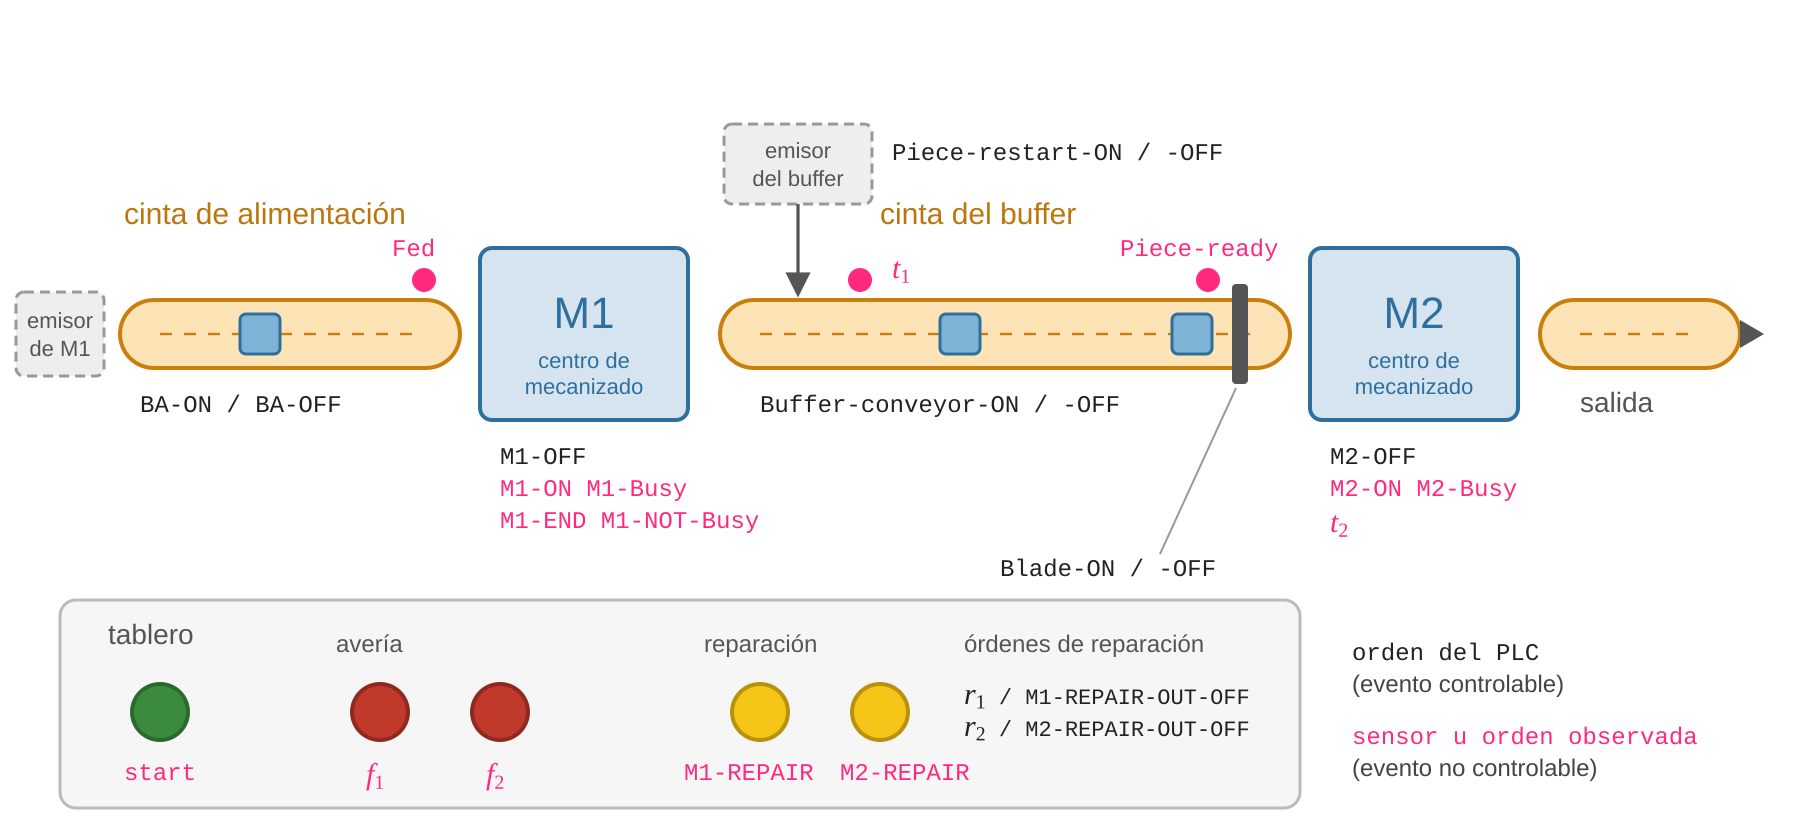

In [ ]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

In [2]:
from deslab import *

## 1. Eventos

Son los del notebook monolítico. El supervisor de las máquinas da directamente las órdenes de
arranque `M1-ON` y `M2-ON`; las llegadas, averías y reparaciones llevan los nombres del notebook de
clase [`LCS_modular_control_small_factory`](../LCS_modular_control_small_factory.ipynb):

| Evento | Significado | Tipo |
|---|---|---|
| `M1-ON`, `M2-ON` | orden de arranque: $M_1$ o $M_2$ toma una pieza y trabaja | controlable |
| $t_1$ | la pieza de $M_1$ llega al buffer | no controlable |
| $t_2$ | $M_2$ deja de estar ocupada | no controlable |
| $f_1$, $f_2$ | avería de $M_1$ o de $M_2$ | no controlable |
| $r_1$, $r_2$ | orden de reparación de $M_1$ o de $M_2$ | controlable |
| `M1-NOT-Busy` | $M_1$ liberada | no controlable |
| `BA-ON`, `BA-OFF` | encender y apagar la cinta de alimentación | controlable |
| `Fed` | la pieza pasó el sensor de entrada de $M_1$ | no controlable |
| `M1-END` | $M_1$ deja de estar ocupada | no controlable |
| `start` | pulsador de arranque | no controlable |

Los autómatas auxiliares usan además los eventos de las cintas, la cuchilla, el emisor y la
reparación. Las listas `CONTROLABLES` y `NO_CONTROLABLES` reúnen todos los eventos.

In [3]:
syms('t1 f1 r1 t2 f2 r2')
tabla = [(t1, 't_1'), (f1, 'f_1'), (r1, 'r_1'), (t2, 't_2'), (f2, 'f_2'), (r2, 'r_2')]

# eventos incluidos los de factory
CONTROLABLES = ['M1-OFF', 'Buffer-conveyor-ON', 'Buffer-conveyor-OFF', 'Blade-OFF', 'Blade-ON',
                'Piece-restart-ON', 'Piece-restart-OFF', 'M2-OFF', 'BA-ON', 'BA-OFF', 'M1-ON', 'M2-ON',
                r1, r2, 'R1-PERMITTED', 'R1-NOT-PERMITTED', 'M1-REPAIR-OUT-OFF', 'R2-PERMITTED',
                'R2-NOT-PERMITTED', 'M2-REPAIR-OUT-OFF']
NO_CONTROLABLES = ['M1-Busy', 'M1-END', 'start', 'Piece-ready', t2, t1, f1, 'M2-Busy', 'Fed', 'M1-NOT-Busy', f2, 'M1-REPAIR', 'M2-REPAIR']

## 2. Planta y especificaciones

Son las del notebook monolítico. La planta tiene cuatro componentes: las máquinas `model_M1` y
`model_M2` (estados 0 libre, 1 trabajando y 2 averiada), la cinta de alimentación `B_A` (se
enciende, la pieza entra a $M_1$, se apaga y espera que $M_1$ termine) y el pulsador de arranque
`pulsador`, con un solo estado y el autolazo de `start`. Las especificaciones son tres:

| Especificación | Qué pide |
|---|---|
| `REQ_Buffer` ($E_1$ del notebook de clase) | el buffer guarda a lo sumo dos piezas: cada $t_1$ agrega una y cada `M2-ON` la retira |
| `REQ_start` | no se arranca $M_1$ ni $M_2$ (`M1-ON`, `M2-ON`), ni se enciende la cinta de alimentación (`BA-ON`), antes del pulsador `start` |
| `REQ_repair` ($E_2$ del notebook de clase) | después de $f_2$, no se repara $M_1$ ($r_1$) antes que $M_2$ ($r_2$) |

El notebook monolítico explica los autolazos y por qué el pulsador es un componente de la planta.
Como allí, $r_1$ y $r_2$ no son eventos de la planta y los supervisores no los generan; la
prioridad de reparación la impone el autómata auxiliar `repair`.

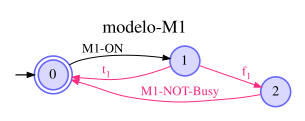

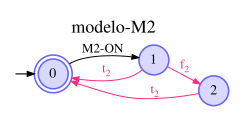

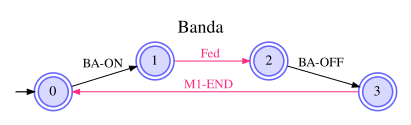

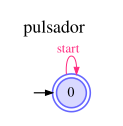

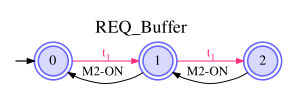

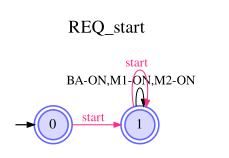

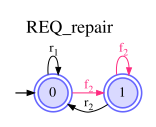

In [4]:
model_M1 = fsa([0, 1, 2], ['M1-ON', t1, f1, 'M1-NOT-Busy'],
               [(0, 'M1-ON', 1), (1, t1, 0), (1, f1, 2), (2, 'M1-NOT-Busy', 0)],
               [0], [0], tabla, Sigcon=['M1-ON'], name='modelo-M1')
model_M2 = fsa([0, 1, 2], ['M2-ON', t2, f2],
               [(0, 'M2-ON', 1), (1, t2, 0), (1, f2, 2), (2, t2, 0)],
               [0], [0], tabla, Sigcon=['M2-ON'], name='modelo-M2')

REQ_Buffer = fsa([0, 1, 2], [t1, 'M2-ON'],
                 [(0, t1, 1), (1, 'M2-ON', 0), (1, t1, 2), (2, 'M2-ON', 1)],
                 [0], [0, 1, 2], tabla, Sigcon=['M2-ON'], name='REQ_Buffer')
REQ_start = fsa([0, 1], ['start', 'M1-ON', 'M2-ON', 'BA-ON'],
                [(0, 'start', 1), (1, 'M1-ON', 1), (1, 'M2-ON', 1), (1, 'BA-ON', 1),
                 (1, 'start', 1)],
                [0], [0, 1], tabla, Sigcon=['M1-ON', 'M2-ON', 'BA-ON'], name='REQ_start')
REQ_repair = fsa([0, 1], [r1, f2, r2],
                 [(0, r1, 0), (0, f2, 1), (1, r2, 0),
                  (1, f2, 1)],
                 [0], [0, 1], tabla, Sigcon=[r1, r2], name='REQ_repair')

B_A = fsa([0, 1, 2, 3], ['BA-ON', 'Fed', 'BA-OFF', 'M1-END'],
          [(0, 'BA-ON', 1), (1, 'Fed', 2), (2, 'BA-OFF', 3), (3, 'M1-END', 0)],
          [0], [0, 1, 2, 3], Sigcon=['BA-ON', 'BA-OFF'], name='Banda')
pulsador = fsa([0], ['start'], [(0, 'start', 0)], [0], [0], Sigcon=set(), name='pulsador')

draw(model_M1, model_M2, B_A, pulsador, REQ_Buffer, REQ_start, REQ_repair)

## 3. Dividir `REQ_start`

Con varios supervisores, el programa del PLC da una orden que comparten dos supervisores solo
cuando los dos la proponen: cada uno escribe su propuesta en un arreglo `_G`, y la orden cambia
cuando las propuestas coinciden. Las propuestas se quedan guardadas, así que, sin parejas que las
borren, la orden ya no se puede apagar. Si un supervisor llevara `REQ_start` completa, compartiría
`M1-ON` y `M2-ON` con el supervisor de las máquinas, y el auxiliar `M1` no podría apagar `M1-ON`.
El notebook [`LCS_local_modular_control_small_factory_openplc`](LCS_local_modular_control_small_factory_openplc.ipynb)
resuelve ese caso con las peticiones internas $e_1$, $e_2$ y las parejas.

Aquí se divide `REQ_start` por equipo, como en TCT: `REQ_start_M` detiene las órdenes de arranque de
las máquinas antes del pulsador, y `REQ_start_BA` la de la cinta. Las dos esperan `start`, que es no
controlable, y su composición es `REQ_start`; la celda lo comprueba.

¿REQ_start es isomorfo a REQ_start_M || REQ_start_BA? True


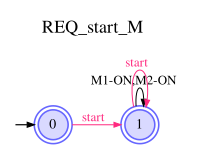

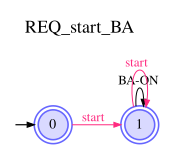

In [5]:
REQ_start_M = fsa([0, 1], ['start', 'M1-ON', 'M2-ON'],
                  [(0, 'start', 1), (1, 'M1-ON', 1), (1, 'M2-ON', 1), (1, 'start', 1)],
                  [0], [0, 1], Sigcon=['M1-ON', 'M2-ON'], name='REQ_start_M')
REQ_start_BA = fsa([0, 1], ['start', 'BA-ON'],
                   [(0, 'start', 1), (1, 'BA-ON', 1), (1, 'start', 1)],
                   [0], [0, 1], Sigcon=['BA-ON'], name='REQ_start_BA')
print('¿REQ_start es isomorfo a REQ_start_M || REQ_start_BA?',
      are_isomorphic(REQ_start, REQ_start_M // REQ_start_BA))
draw(REQ_start_M, REQ_start_BA)

## 4. Los dos supervisores

Cada supervisor se sintetiza con la planta de los equipos que controla, más el pulsador, porque sus
especificaciones esperan `start`:

| Supervisor | Planta | Especificaciones |
|---|---|---|
| `SUP_maq` | `model_M1` $\parallel$ `model_M2` $\parallel$ `pulsador` | `REQ_Buffer`, `REQ_repair`, `REQ_start_M` |
| `sup_BA` | `B_A` $\parallel$ `pulsador` | `REQ_start_BA` |

Los dos solo comparten `start`, que es no controlable: cada uno lo observa y avanza con él, pero no
comparten ninguna orden.

SUP_maq: 36 estados, 119 transiciones | ¿controlable? True | ¿no bloqueante? True
sup_BA: 5 estados, 9 transiciones | ¿controlable? True | ¿no bloqueante? True
eventos compartidos: {'start'}
órdenes compartidas: set()


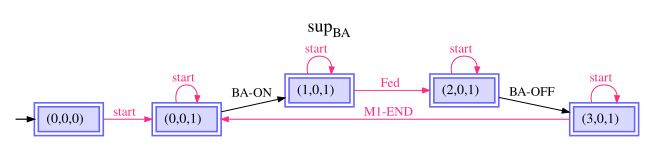

In [6]:
transiciones = lambda S: sum(len(S.Gamma(x)) for x in S.X)

G_maq = model_M1 // model_M2 // pulsador
SUP_maq = supcontrollable(G_maq // REQ_Buffer // REQ_repair // REQ_start_M, G_maq).setpar(
    name='$SUP_{maq}$', style='rectangle')
G_BA = B_A // pulsador
sup_BA = supcontrollable(G_BA // REQ_start_BA, G_BA).setpar(name='$sup_{BA}$', style='rectangle')

for nombre, S, P in [('SUP_maq', SUP_maq, G_maq), ('sup_BA', sup_BA, G_BA)]:
    print(f'{nombre}: {len(S)} estados, {transiciones(S)} transiciones'
          f' | ¿controlable? {iscontrollable(S, P)} | ¿no bloqueante? {coac(S).X == S.X}')
print('eventos compartidos:', set(SUP_maq.Sigma & sup_BA.Sigma))
print('órdenes compartidas:', set(SUP_maq.Sigcon & sup_BA.Sigcon))
draw(sup_BA)

## 5. ¿Es igual al supervisor monolítico?

Los dos supervisores actúan juntos: un evento que los dos conocen ocurre solo si los dos lo
permiten, así que el sistema controlado es `SUP_maq` $\parallel$ `sup_BA`. Si son no conflictivos,
esa composición es el supervisor monolítico, como en la sección 5 del notebook de clase. La celda
sintetiza el supervisor monolítico $SUP$ como en el notebook monolítico, y comprueba que los dos
supervisores son no conflictivos y que `SUP_maq` $\parallel$ `sup_BA` es isomorfo a $SUP$.

Las dos formas tienen el mismo comportamiento, pero no el mismo tamaño: $SUP$ tiene un estado por
cada combinación alcanzable de los estados de `SUP_maq` y `sup_BA`.

In [7]:
G = model_M1 // model_M2 // B_A // pulsador
SUP = supcontrollable(G // REQ_Buffer // REQ_start // REQ_repair, G)
print('SUP monolítico:', len(SUP), 'estados,', transiciones(SUP), 'transiciones')
print('¿SUP_maq y sup_BA son no conflictivos?', nonconflict(SUP_maq, sup_BA))
print('¿SUP_maq || sup_BA es isomorfo a SUP?', are_isomorphic(SUP_maq // sup_BA, SUP))

SUP monolítico: 141 estados, 613 transiciones
¿SUP_maq y sup_BA son no conflictivos? True
¿SUP_maq || sup_BA es isomorfo a SUP? True


## 6. Autómatas auxiliares

Son los del notebook monolítico. Como allí, `sup_BA` no es un auxiliar sino un supervisor:

| Autómata | Qué hace |
|---|---|
| `M1`, `M2` | cuando el supervisor da la orden de arranque (`Mi-ON`) y la máquina lo confirma (`Mi-Busy`), apaga la orden (`Mi-OFF`) y espera que deje de estar ocupada (`M1-END` o $t_2$) |
| `generate` | cuando $M_1$ termina, enciende el emisor del buffer (`Piece-restart-ON`) hasta que la pieza llega al sensor ($t_1$); si $M_1$ se avería ($f_1$), no hay pieza |
| `Buffer_fill` | mueve la cinta del buffer: lleva la primera pieza hasta la cuchilla (`Piece-ready`) y avanza cada pieza nueva más allá del sensor de entrada ($t_1$); cuando $M_2$ termina ($t_2$), vuelve a avanzar |
| `Blade` | cuando $M_2$ termina ($t_2$), baja la cuchilla (`Blade-OFF`) hasta que pasa la pieza (`Piece-ready`) y la vuelve a subir |
| `repair` | cuando una máquina se avería ($f_i$), permite su reparación, espera el pulsador (`Mi-REPAIR`), da la orden de reparación ($r_i$) hasta que la máquina queda libre y la apaga; si $M_2$ se avería mientras $M_1$ espera, primero se repara $M_2$ |

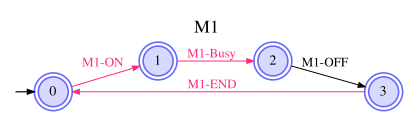

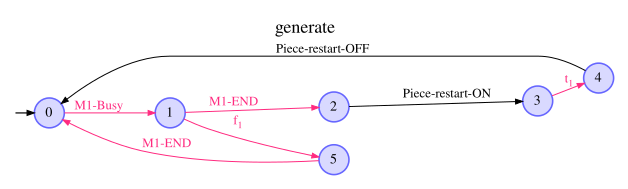

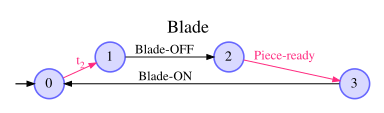

In [8]:
M1 = fsa([0, 1, 2, 3], ['M1-ON', 'M1-Busy', 'M1-OFF', 'M1-END'],
         [(0, 'M1-ON', 1), (1, 'M1-Busy', 2), (2, 'M1-OFF', 3), (3, 'M1-END', 0)],
         [0], [0, 1, 2, 3], Sigcon=['M1-OFF'], name='M1')
M2 = fsa([0, 1, 2, 3], ['M2-ON', 'M2-Busy', 'M2-OFF', t2],
         [(0, 'M2-ON', 1), (1, 'M2-Busy', 2), (2, 'M2-OFF', 3), (3, t2, 0)],
         [0], [0, 1, 2, 3], tabla, Sigcon=['M2-OFF'], name='M2')

T_generate = [(0, 'M1-Busy', 1), (1, 'M1-END', 2), (2, 'Piece-restart-ON', 3), (3, t1, 4),
              (4, 'Piece-restart-OFF', 0), (1, f1, 5), (5, 'M1-END', 0)]
generate = fsa(list(range(6)), {e for _, e, _ in T_generate}, T_generate, [0], [], tabla,
               Sigcon=['Piece-restart-ON', 'Piece-restart-OFF'], name='generate')

T_buffer_fill = [(0, 'start', 1), (1, 'M1-END', 2), (2, 'Buffer-conveyor-ON', 3), (3, 'Piece-ready', 4),
                 (4, 'Buffer-conveyor-OFF', 5), (5, t2, 2), (7, t2, 2), (5, 'M1-END', 6),
                 (6, 'Buffer-conveyor-ON', 7), (7, t1, 8), (8, 'Buffer-conveyor-OFF', 5),
                 (1, f1, 9), (9, 'M1-END', 1)]
Buffer_fill = fsa(list(range(10)), {e for _, e, _ in T_buffer_fill}, T_buffer_fill, [0], list(range(10)),
                  tabla, Sigcon=['Buffer-conveyor-ON', 'Buffer-conveyor-OFF'], name='Buffer_fill')

Blade = fsa([0, 1, 2, 3], [t2, 'Blade-OFF', 'Piece-ready', 'Blade-ON'],
            [(0, t2, 1), (1, 'Blade-OFF', 2), (2, 'Piece-ready', 3), (3, 'Blade-ON', 0)],
            [0], [], tabla, Sigcon=['Blade-OFF', 'Blade-ON'], name='Blade')

T_repair = [(0, f1, 1), (1, 'R1-PERMITTED', 2), (2, 'M1-REPAIR', 3),
            (3, r1, 4), (4, 'R1-NOT-PERMITTED', 5), (5, 'M1-NOT-Busy', 6),
            (6, 'M1-REPAIR-OUT-OFF', 0),
            (0, f2, 7), (7, 'R2-PERMITTED', 8), (8, 'M2-REPAIR', 9),
            (9, r2, 10), (10, 'R2-NOT-PERMITTED', 11), (11, t2, 12),
            (12, 'M2-REPAIR-OUT-OFF', 0),
            # M2 se avería mientras M1 espera su reparación: primero se repara M2
            (2, f2, 13), (13, 'R1-NOT-PERMITTED', 14), (14, 'R2-PERMITTED', 15),
            (15, 'M2-REPAIR', 16), (16, r2, 17), (17, 'R2-NOT-PERMITTED', 18),
            (18, t2, 19), (19, 'M2-REPAIR-OUT-OFF', 1),
            # M1 se avería mientras M2 espera la suya
            (8, f1, 15)]
repair = fsa(list(range(20)), {e for _, e, _ in T_repair}, T_repair, [0], list(range(20)), tabla,
             Sigcon=['R1-PERMITTED', r1, 'R1-NOT-PERMITTED', 'M1-REPAIR-OUT-OFF',
                     'R2-PERMITTED', r2, 'R2-NOT-PERMITTED', 'M2-REPAIR-OUT-OFF'],
             name='repair')

auxiliares = [M1, M2, generate, Buffer_fill, Blade, repair]
draw(M1, generate, Blade)

## 7. Mapa de señales

Es el del notebook monolítico: `Variable:ON:dirección` y `Variable:OFF` escriben 1 y 0 en una
salida o, en una entrada, observan su nivel; `FE_Nombre:Entrada:dirección` es el flanco de bajada
de una entrada, e `INTERN_k` una variable interna. Cada supervisor escribe directamente sus
órdenes: `SUP_maq` las de arranque `M1-ON` y `M2-ON` (`GD_OUT_0` y `GD_OUT_1`), que los
auxiliares `M1` y `M2` apagan cuando la máquina confirma el arranque, y `sup_BA` las de la cinta,
`BA-ON` y `BA-OFF` (`GD_OUT_2`). `Mask` copia en cada scan la cinta de alimentación en su emisor y
cada avería en una salida.

In [9]:
actuators = {
    'M1-ON': 'GD_OUT_0:ON:%QX100.0', 'M1-OFF': 'GD_OUT_0:OFF',
    'M2-ON': 'GD_OUT_1:ON:%QX100.1', 'M2-OFF': 'GD_OUT_1:OFF',
    'M1-Busy': 'GD_IN_0:ON:%IX100.0', 'M1-NOT-Busy': 'GD_IN_0:OFF:%IX100.0',
    'M2-Busy': 'GD_IN_1:ON:%IX100.1',
    'M1-END': 'FE_M1E:GD_IN_0:%IX100.0', t2: 'FE_M2E:GD_IN_1:%IX100.1',
    'start': 'GD_IN_15:ON:%IX100.5',
    'BA-ON': 'GD_OUT_2:ON:%QX100.2', 'BA-OFF': 'GD_OUT_2:OFF',
    'Fed': 'FE_A:GD_IN_2:%IX100.2',
    'Buffer-conveyor-ON': 'GD_OUT_4:ON:%QX100.4', 'Buffer-conveyor-ON-UC': 'GD_OUT_4:ON:%QX100.4',
    'Buffer-conveyor-OFF': 'GD_OUT_4:OFF',
    t1: 'FE_PL:GD_IN_3:%IX100.3', 'Piece-ready': 'FE_PR:GD_IN_4:%IX100.4',
    'Piece-restart-ON': 'GD_OUT_5:ON:%QX100.5', 'Piece-restart-OFF': 'GD_OUT_5:OFF:%QX100.5',
    'Blade-ON': 'GD_OUT_6:ON:%QX100.6', 'Blade-OFF': 'GD_OUT_6:OFF:%QX100.6',
    f1: 'GD_IN_10:OFF:%IX101.0', f2: 'GD_IN_11:OFF:%IX101.1',
    'M1-REPAIR': 'GD_IN_12:ON:%IX101.2', 'M2-REPAIR': 'GD_IN_13:ON:%IX101.3',
    'M1-REPAIR-DONE': 'INTERN_4:OFF', 'M2-REPAIR-DONE': 'INTERN_5:OFF',
    r1: 'GD_OUT_10:ON:%QX101.2', r2: 'GD_OUT_11:ON:%QX101.3',
    'M1-REPAIR-OUT-OFF': 'GD_OUT_10:OFF:%QX101.2', 'M2-REPAIR-OUT-OFF': 'GD_OUT_11:OFF:%QX101.3',
    'R1-PERMITTED': 'INTERN_2:ON', 'R2-PERMITTED': 'INTERN_3:ON',
    'R1-NOT-PERMITTED': 'INTERN_2:OFF', 'R2-NOT-PERMITTED': 'INTERN_3:OFF',
}
Mask = {'GD_OUT_2': [('GD_OUT_3', '%QX100.3')],
        'NOT GD_IN_10': [('GD_OUT_8', '%QX101.0')],
        'NOT GD_IN_11': [('GD_OUT_9', '%QX101.1')]}

## 8. Generar el programa

| Parámetro | Valor |
|---|---|
| `supervisors`, `plants` | `[SUP_maq, sup_BA]` y `[G_maq, G_BA]`: cada supervisor con su planta, en el mismo orden |
| `Isolated` | `auxiliares`: los autómatas auxiliares |
| `initial` | `'start'`: el programa espera el pulsador de arranque antes de empezar |

`state[0]` es `SUP_maq`, `state[1]` es `sup_BA` y `state[2]` a `state[7]` son los auxiliares en el
orden de la lista. El generador revisa si los supervisores son conflictivos; no lo son, así que no
agrega coordinador. Como no comparten órdenes, el programa no tiene arreglos `_G` ni parejas: cada
supervisor escribe sus salidas, como el monolítico.

In [10]:
from pathlib import Path

carpeta = Path('ST_Generated')
nombre = 'Small_factory_modular_equipos'
st = generate_ST_OPENPLC([SUP_maq, sup_BA], plants=[G_maq, G_BA], actuators=actuators,
                         namest=nombre, Mask=Mask, Isolated=auxiliares, initial='start',
                         output_dir=carpeta)
archivo = carpeta / f'{nombre}.st'
print('programa guardado en', archivo)
print('líneas:', len(st.splitlines()))
print('¿Hay coordinador?', '_C :' in st, '| ¿Hay órdenes compartidas?', '_G :' in st)

programa guardado en ST_Generated/Small_factory_modular_equipos.st
líneas: 528
¿Hay coordinador? False | ¿Hay órdenes compartidas? False


In [11]:
print(st)
# en Colab se descarga el archivo; en Jupyter queda un enlace
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(str(archivo)))

FUNCTION_BLOCK random_number
	VAR_INPUT
		IN : BOOL;
	END_VAR
	VAR
		M : BOOL;
		INIT : BOOL;
	END_VAR
	VAR_OUTPUT
		OUT : DINT;
	END_VAR

	IF INIT = 0 THEN
		{#include <stdio.h>}
		{#include <stdlib.h>}
		IN := 1;
	END_IF;
	IF M = 0 and IN = 1 THEN
		{SetFbVar(OUT,rand())}
	END_IF;
END_FUNCTION_BLOCK
PROGRAM supcon
	VAR
		random : random_number;
		random_num : DINT;
		initial : BOOL;
		state : ARRAY [0..8] OF DINT;
		slt0 : ARRAY [0..2] OF DINT;
		FE_M1E : F_TRIG;
		FE_M2E : F_TRIG;
		FE_A : F_TRIG;
		FE_PL : F_TRIG;
		FE_PR : F_TRIG;
		INTERN_4 : BOOL;
		INTERN_5 : BOOL;
		INTERN_2 : BOOL;
		INTERN_3 : BOOL;
	END_VAR
	VAR
		GD_OUT_3 AT %QX100.3 : BOOL;
 		GD_OUT_8 AT %QX101.0 : BOOL;
 		GD_OUT_9 AT %QX101.1 : BOOL;
 		GD_OUT_0 AT %QX100.0 : BOOL;
		GD_OUT_1 AT %QX100.1 : BOOL;
		GD_IN_0 AT %IX100.0 : BOOL;
		GD_IN_1 AT %IX100.1 : BOOL;
		GD_IN_15 AT %IX100.5 : BOOL;
		GD_OUT_2 AT %QX100.2 : BOOL;
		GD_IN_2 AT %IX100.2 : BOOL;
		GD_OUT_4 AT %QX100.4 : BOOL;
		GD_IN_3 AT %IX100.3 : BOO

ST_Generated/Small_factory_modular_equipos.st

## 9. Dos supervisores en el PLC

El programa implementa el mismo comportamiento que el del supervisor monolítico, pero cada
supervisor tiene su propia variable de estado:

* **Dos órdenes en el mismo scan.** En el monolítico, si están habilitadas `M1-ON` y `BA-ON`, el
  programa elige una al azar y da la otra en un scan posterior. Aquí cada supervisor da la suya en
  el mismo scan.
* **Eventos no controlables.** Cada supervisor avanza con a lo sumo un evento no controlable por
  scan. `sup_BA` solo sigue la cinta de alimentación (`Fed`, `M1-END`) y el pulsador, y `SUP_maq`
  las máquinas. Si `Fed` y $t_2$ llegan en el mismo scan, cada supervisor procesa el suyo, mientras
  que el monolítico pierde uno. Dos eventos de las máquinas en el mismo scan, por ejemplo $t_1$ y
  $t_2$, se siguen perdiendo en `SUP_maq`.
* **Tamaño.** `SUP_maq` y `sup_BA` tienen 36 + 5 estados en lugar de los 141 de $SUP$, y el
  programa tiene 528 líneas en lugar de 1703.

Frente al notebook de control modular local, aquí no hay órdenes compartidas: no hacen falta las
peticiones $e_1$ y $e_2$ ni las parejas, a cambio de dividir `REQ_start`.

La prueba `tests/test_openplc_notebooks.py` del repositorio ejecuta las celdas de este notebook y
comprueba que los dos supervisores son controlables, no bloqueantes y no conflictivos, que solo
comparten `start`, que su composición es isomorfa al supervisor monolítico, que los eventos, los
modelos, los auxiliares y el mapa de señales son los del notebook monolítico y que el programa es el
que está en la carpeta `ST_generated`.

Para llevarlo a OpenPLC, importe el archivo `.st`, compílelo y asigne las direcciones de la
escena. Las pruebas en la escena son las mismas de los otros notebooks: siga una pieza desde la
alimentación hasta $M_2$ y simule averías de cada máquina y de las dos.